EXPERIMENT 10 — BPSK, QPSK AND DBPSK

1. BPSK IMPLEMENTATION
BPSK Mapping:
Bit 0 -> +1
Bit 1 -> -1

BPSK SNR = 8 dB
BPSK BER = 0.000250


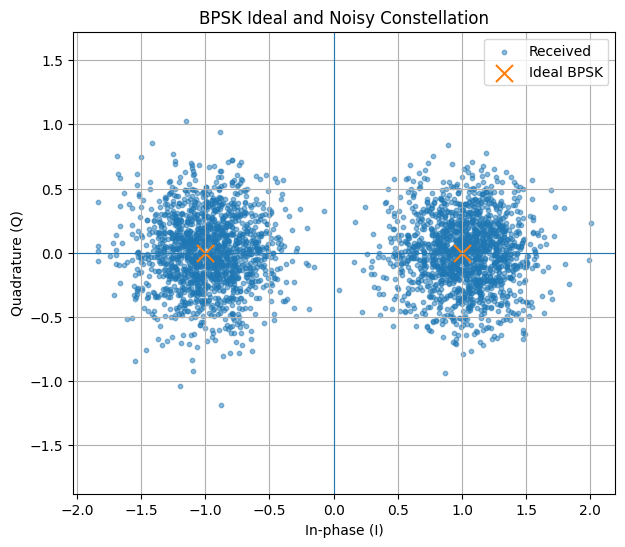


GRAPH EXPLANATION:
The BPSK constellation has two ideal points at +1 and -1 on the
I-axis. AWGN spreads the received symbols around these two points.
The detector decides 0 for positive I and 1 for negative I.


2. GRAY-CODED QPSK MAPPING

QPSK Gray Mapping:
----------------------------------------
00 -> I=+0.707, Q=+0.707, Phase=45.0°
01 -> I=-0.707, Q=+0.707, Phase=135.0°
11 -> I=-0.707, Q=-0.707, Phase=225.0°
10 -> I=+0.707, Q=-0.707, Phase=315.0°

3. MANDATORY QPSK MAPPER/DETECTOR VALIDATION

Testing 00, 01, 11 and 10 manually...

Input 00 -> Symbol (+0.707, +0.707) -> Detected 00 -> PASS
Input 01 -> Symbol (-0.707, +0.707) -> Detected 01 -> PASS
Input 11 -> Symbol (-0.707, -0.707) -> Detected 11 -> PASS
Input 10 -> Symbol (+0.707, -0.707) -> Detected 10 -> PASS

✓ MANDATORY VALIDATION PASSED


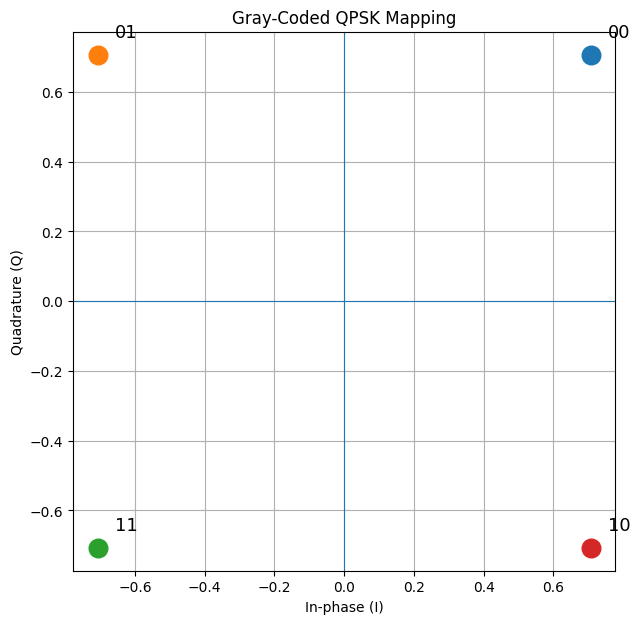


GRAPH EXPLANATION:
QPSK carries two bits per symbol. The four symbols are separated
by 90 degrees. Adjacent constellation points differ by only one
bit, which is the main advantage of Gray coding.


4. QPSK COHERENT DETECTION
QPSK SNR = 8 dB
QPSK BER = 0.006000


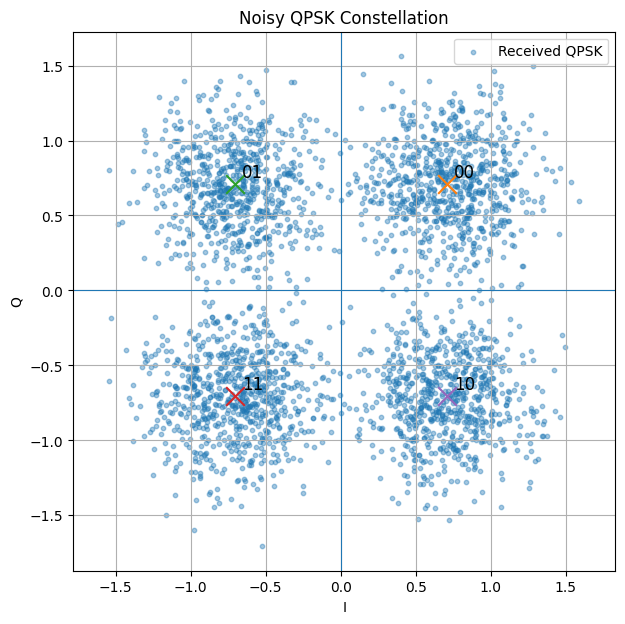


GRAPH EXPLANATION:
The four clusters represent the four QPSK symbols. Noise spreads
the points around their ideal locations. If noise moves a symbol
across a decision boundary, the detector produces a bit error.


5. QPSK CARRIER PHASE OFFSET ANALYSIS
Phase Offset =  10° --> BER = 0.011200
Phase Offset =  30° --> BER = 0.088400
Phase Offset =  60° --> BER = 0.410200
Phase Offset =  90° --> BER = 0.499800


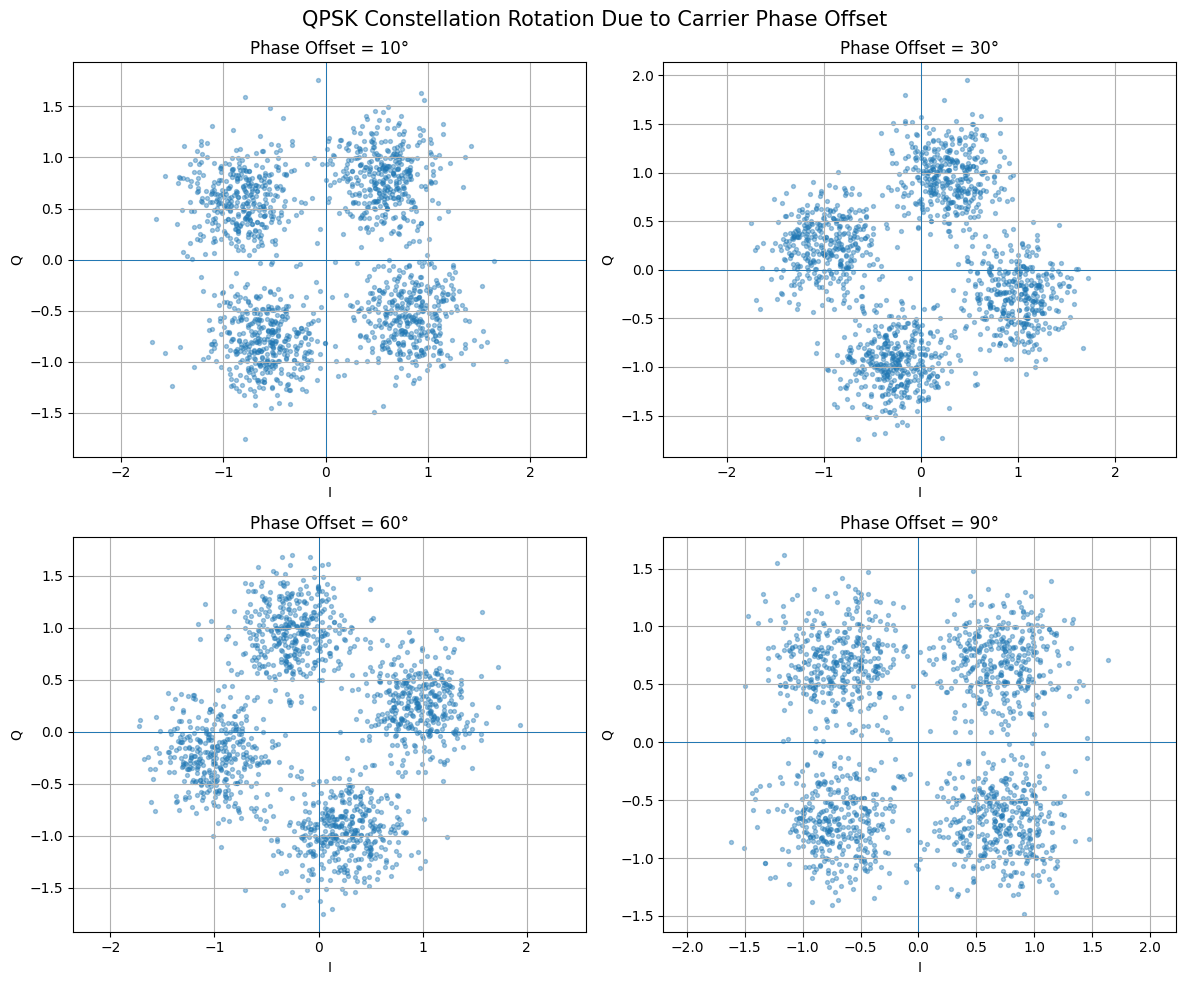


GRAPH EXPLANATION:
A carrier phase offset rotates the entire QPSK constellation.
At small offsets the received points remain close to their
original decision regions. As the offset increases, the points
move closer to incorrect decision regions and BER increases.


6. DBPSK DIFFERENTIAL ENCODING
DBPSK Differential Mapping:
Bit 0 -> 0° phase change
Bit 1 -> 180° phase change


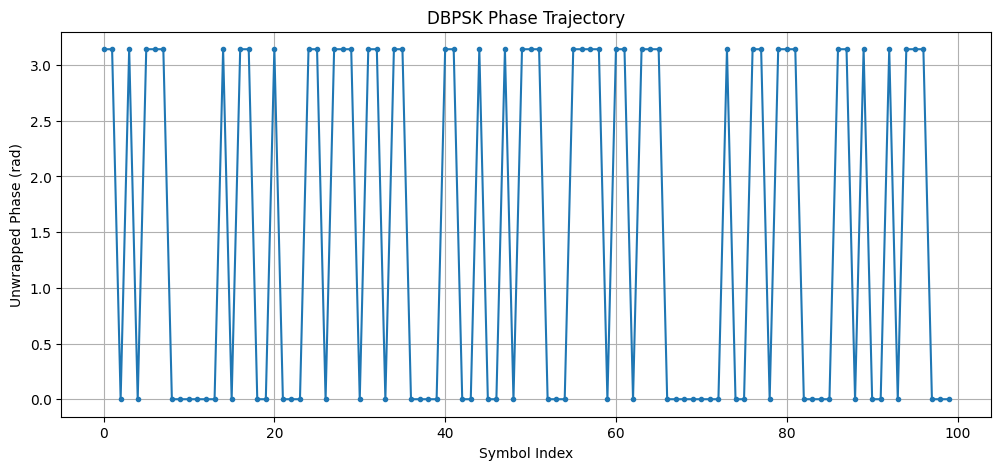


GRAPH EXPLANATION:
In DBPSK, information is represented by the phase difference
between consecutive symbols. A transmitted 0 maintains the phase,
while a transmitted 1 introduces a 180-degree phase change.


7. DBPSK DETECTION
DBPSK SNR = 8 dB
DBPSK BER = 0.000650

8. DBPSK PHASE OFFSET ANALYSIS
Phase Offset =  10° --> DBPSK BER = 0.000750
Phase Offset =  30° --> DBPSK BER = 0.000600
Phase Offset =  60° --> DBPSK BER = 0.000350
Phase Offset =  90° --> DBPSK BER = 0.000650


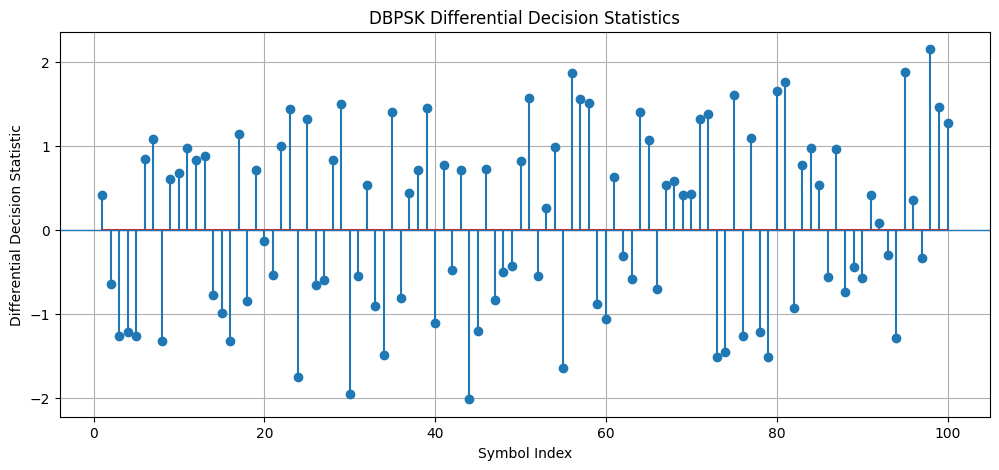


GRAPH EXPLANATION:
The differential decision statistic is positive when consecutive
symbols have approximately the same phase, corresponding to bit 0.
It becomes negative when the phase changes by approximately 180°,
corresponding to bit 1.



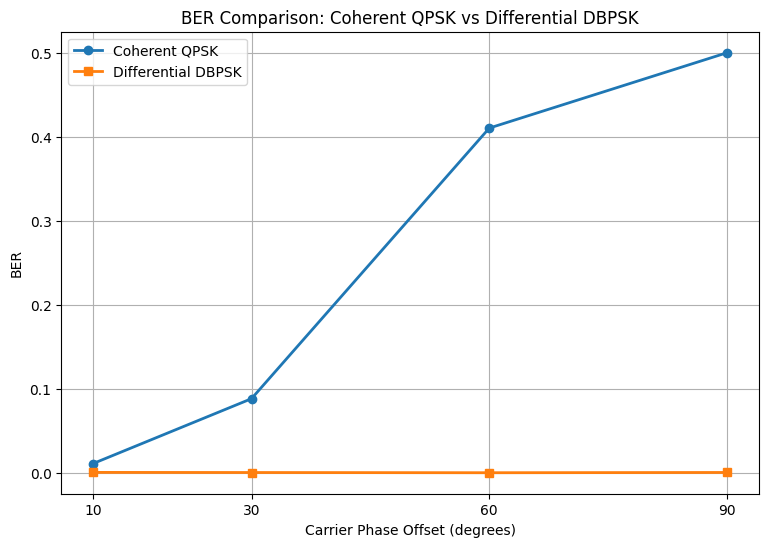

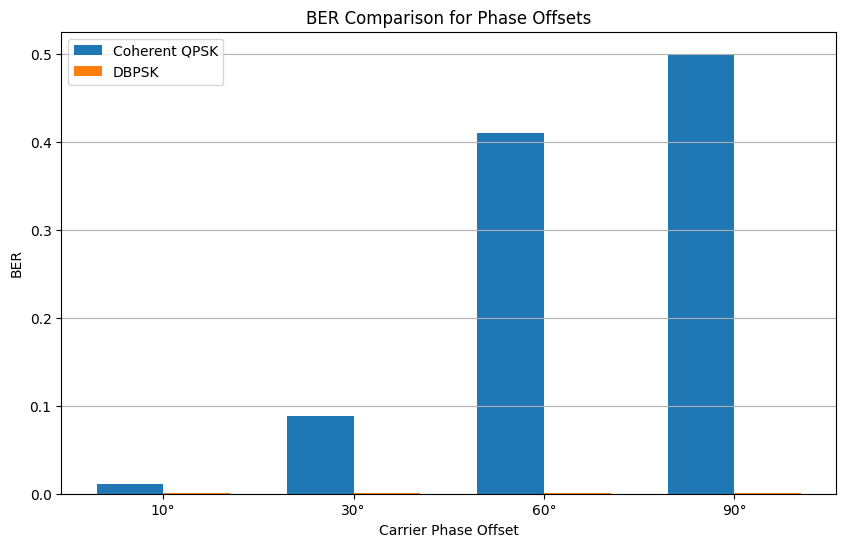

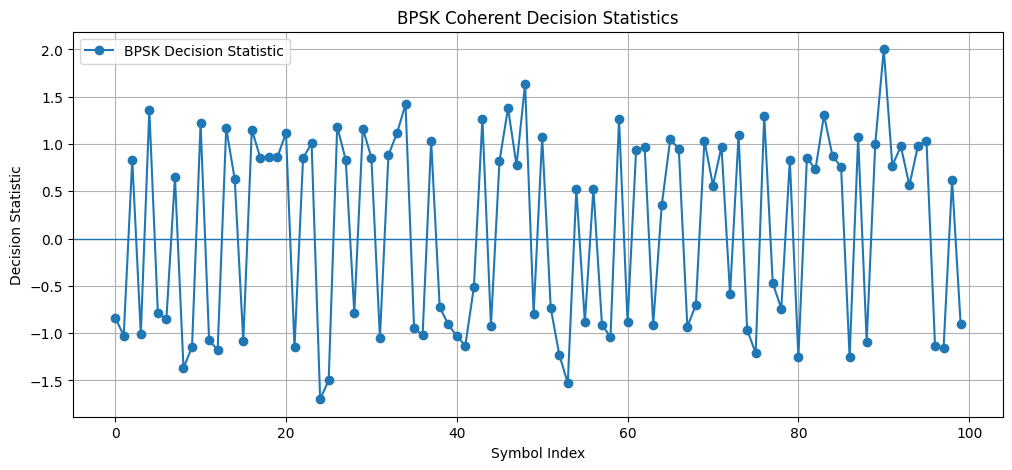


9. EXPECTED PHYSICAL EFFECT

10°:
Expected -> Small constellation rotation; small degradation in coherent detection.

30°:
Expected -> Greater rotation; decision margin decreases.

60°:
Expected -> Large rotation; symbols approach incorrect decision regions.

90°:
Expected -> One-quadrant rotation; severe coherent detection errors can occur.

10. OBSERVATION AND INTERPRETATION

BPSK:
The BPSK constellation consists of two antipodal points. AWGN
creates a spread around these points. Coherent detection uses the
sign of the received in-phase component.

QPSK:
QPSK transmits two bits per symbol using four phase states.
The Gray-coded mapping ensures neighboring symbols differ by one
bit, reducing the average bit error impact of symbol errors.

PHASE OFFSET:
A carrier phase offset rotates the received constellation.
Coherent detection assumes a correct carrier phase reference.
Therefore, increasing phase offset reduces the decision margin
and can increase BER.

DBPSK:
DBPSK detects informa

In [1]:
# ============================================================
# EXPERIMENT 10 — BPSK, QPSK AND DPSK
# Digital Communication Laboratory
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

np.random.seed(10)

# ============================================================
# 1. PARAMETERS
# ============================================================

N_BITS = 20000
SNR_dB = 8

PHASE_OFFSETS_DEG = [10, 30, 60, 90]

print("=" * 65)
print("EXPERIMENT 10 — BPSK, QPSK AND DBPSK")
print("=" * 65)

# ============================================================
# 2. HELPER FUNCTIONS
# ============================================================

def add_awgn(signal, snr_db):
    """
    Add complex AWGN for normalized signal.
    """
    signal_power = np.mean(np.abs(signal)**2)
    snr_linear = 10**(snr_db / 10)
    noise_power = signal_power / snr_linear

    noise = np.sqrt(noise_power / 2) * (
        np.random.randn(*signal.shape) +
        1j * np.random.randn(*signal.shape)
    )

    return signal + noise


def ber(original, detected):
    return np.mean(original != detected)


# ============================================================
# 3. BPSK
# ============================================================

print("\n" + "=" * 65)
print("1. BPSK IMPLEMENTATION")
print("=" * 65)

# Generate random bits
bpsk_bits = np.random.randint(0, 2, N_BITS)

# Normalized BPSK mapping
# 0 -> +1
# 1 -> -1
bpsk_symbols = 1 - 2 * bpsk_bits

print("BPSK Mapping:")
print("Bit 0 -> +1")
print("Bit 1 -> -1")

# Add AWGN
bpsk_received = add_awgn(
    bpsk_symbols.astype(complex),
    SNR_dB
)

# ------------------------------------------------------------
# Coherent BPSK detection
# ------------------------------------------------------------

bpsk_detected = (np.real(bpsk_received) < 0).astype(int)

bpsk_ber = ber(bpsk_bits, bpsk_detected)

print(f"\nBPSK SNR = {SNR_dB} dB")
print(f"BPSK BER = {bpsk_ber:.6f}")

# ============================================================
# 4. BPSK CONSTELLATION
# ============================================================

plt.figure(figsize=(7, 6))

plt.scatter(
    np.real(bpsk_received[:3000]),
    np.imag(bpsk_received[:3000]),
    s=10,
    alpha=0.5,
    label="Received"
)

plt.scatter(
    [1, -1],
    [0, 0],
    s=150,
    marker="x",
    label="Ideal BPSK"
)

plt.axhline(0, linewidth=0.8)
plt.axvline(0, linewidth=0.8)

plt.xlabel("In-phase (I)")
plt.ylabel("Quadrature (Q)")
plt.title("BPSK Ideal and Noisy Constellation")
plt.grid(True)
plt.legend()
plt.axis("equal")
plt.show()

print("""
GRAPH EXPLANATION:
The BPSK constellation has two ideal points at +1 and -1 on the
I-axis. AWGN spreads the received symbols around these two points.
The detector decides 0 for positive I and 1 for negative I.
""")


# ============================================================
# 5. GRAY-CODED QPSK MAPPING
# ============================================================

print("\n" + "=" * 65)
print("2. GRAY-CODED QPSK MAPPING")
print("=" * 65)

# Normalized Gray-coded QPSK
# Each symbol has unit magnitude.
#
# 00 -> +1 + j
# 01 -> -1 + j
# 11 -> -1 - j
# 10 -> +1 - j

qpsk_map = {
    (0, 0): (1 + 1j) / np.sqrt(2),
    (0, 1): (-1 + 1j) / np.sqrt(2),
    (1, 1): (-1 - 1j) / np.sqrt(2),
    (1, 0): (1 - 1j) / np.sqrt(2)
}

qpsk_demapper = {
    1: (0, 0),
    2: (0, 1),
    3: (1, 1),
    4: (1, 0)
}

print("\nQPSK Gray Mapping:")
print("-" * 40)

for bits, symbol in qpsk_map.items():

    phase = np.degrees(np.angle(symbol)) % 360

    print(
        f"{bits[0]}{bits[1]} -> "
        f"I={np.real(symbol):+.3f}, "
        f"Q={np.imag(symbol):+.3f}, "
        f"Phase={phase:.1f}°"
    )


# ============================================================
# 6. MANDATORY MANUAL VALIDATION
# ============================================================

print("\n" + "=" * 65)
print("3. MANDATORY QPSK MAPPER/DETECTOR VALIDATION")
print("=" * 65)

print("\nTesting 00, 01, 11 and 10 manually...\n")


def qpsk_detect(symbol):
    """
    Coherent QPSK detector.
    Decision is based on signs of I and Q.
    """

    I = np.real(symbol)
    Q = np.imag(symbol)

    if I >= 0 and Q >= 0:
        return (0, 0)

    elif I < 0 and Q >= 0:
        return (0, 1)

    elif I < 0 and Q < 0:
        return (1, 1)

    else:
        return (1, 0)


validation_pass = True

for bits in [(0, 0), (0, 1), (1, 1), (1, 0)]:

    tx = qpsk_map[bits]
    detected = qpsk_detect(tx)

    status = "PASS" if detected == bits else "FAIL"

    if detected != bits:
        validation_pass = False

    print(
        f"Input {bits[0]}{bits[1]} -> "
        f"Symbol ({np.real(tx):+.3f}, {np.imag(tx):+.3f}) -> "
        f"Detected {detected[0]}{detected[1]} -> {status}"
    )

print()

if validation_pass:
    print("✓ MANDATORY VALIDATION PASSED")
else:
    print("✗ MANDATORY VALIDATION FAILED")


# ============================================================
# 7. QPSK MAPPING PLOT
# ============================================================

plt.figure(figsize=(7, 7))

for bits, symbol in qpsk_map.items():

    plt.scatter(
        np.real(symbol),
        np.imag(symbol),
        s=180
    )

    plt.text(
        np.real(symbol) + 0.05,
        np.imag(symbol) + 0.05,
        f"{bits[0]}{bits[1]}",
        fontsize=13
    )

plt.axhline(0, linewidth=0.8)
plt.axvline(0, linewidth=0.8)

plt.xlabel("In-phase (I)")
plt.ylabel("Quadrature (Q)")
plt.title("Gray-Coded QPSK Mapping")
plt.grid(True)
plt.axis("equal")
plt.show()

print("""
GRAPH EXPLANATION:
QPSK carries two bits per symbol. The four symbols are separated
by 90 degrees. Adjacent constellation points differ by only one
bit, which is the main advantage of Gray coding.
""")


# ============================================================
# 8. GENERATE QPSK SIGNAL
# ============================================================

qpsk_bits = np.random.randint(0, 2, N_BITS)

# Make number of bits even
if len(qpsk_bits) % 2 != 0:
    qpsk_bits = qpsk_bits[:-1]

# Group bits into pairs
bit_pairs = qpsk_bits.reshape(-1, 2)

qpsk_symbols = np.array([
    qpsk_map[tuple(pair)]
    for pair in bit_pairs
])

# Add noise
qpsk_received = add_awgn(qpsk_symbols, SNR_dB)


# ============================================================
# 9. QPSK COHERENT DETECTION
# ============================================================

qpsk_detected_pairs = np.array([
    qpsk_detect(symbol)
    for symbol in qpsk_received
])

qpsk_detected_bits = qpsk_detected_pairs.flatten()

qpsk_ber = ber(
    qpsk_bits,
    qpsk_detected_bits
)

print("\n" + "=" * 65)
print("4. QPSK COHERENT DETECTION")
print("=" * 65)

print(f"QPSK SNR = {SNR_dB} dB")
print(f"QPSK BER = {qpsk_ber:.6f}")


# ============================================================
# 10. NOISY QPSK CONSTELLATION
# ============================================================

plt.figure(figsize=(7, 7))

plt.scatter(
    np.real(qpsk_received[:3000]),
    np.imag(qpsk_received[:3000]),
    s=10,
    alpha=0.4,
    label="Received QPSK"
)

for bits, symbol in qpsk_map.items():

    plt.scatter(
        np.real(symbol),
        np.imag(symbol),
        s=180,
        marker="x"
    )

    plt.text(
        np.real(symbol) + 0.05,
        np.imag(symbol) + 0.05,
        f"{bits[0]}{bits[1]}",
        fontsize=12
    )

plt.axhline(0, linewidth=0.8)
plt.axvline(0, linewidth=0.8)

plt.xlabel("I")
plt.ylabel("Q")
plt.title("Noisy QPSK Constellation")
plt.grid(True)
plt.legend()
plt.axis("equal")
plt.show()

print("""
GRAPH EXPLANATION:
The four clusters represent the four QPSK symbols. Noise spreads
the points around their ideal locations. If noise moves a symbol
across a decision boundary, the detector produces a bit error.
""")


# ============================================================
# 11. QPSK PHASE OFFSET ANALYSIS
# ============================================================

print("\n" + "=" * 65)
print("5. QPSK CARRIER PHASE OFFSET ANALYSIS")
print("=" * 65)

qpsk_offset_ber = []

# Use the same symbols for all offsets
# This makes comparison fair.

for offset_deg in PHASE_OFFSETS_DEG:

    offset_rad = np.radians(offset_deg)

    # Apply phase rotation
    rotated = qpsk_symbols * np.exp(1j * offset_rad)

    # Add AWGN
    received = add_awgn(rotated, SNR_dB)

    # Coherent detector WITHOUT phase correction
    detected_pairs = np.array([
        qpsk_detect(symbol)
        for symbol in received
    ])

    detected_bits = detected_pairs.flatten()

    current_ber = ber(
        qpsk_bits,
        detected_bits
    )

    qpsk_offset_ber.append(current_ber)

    print(
        f"Phase Offset = {offset_deg:>3}° "
        f"--> BER = {current_ber:.6f}"
    )


# ============================================================
# 12. QPSK CONSTELLATION ROTATION
# ============================================================

fig, axes = plt.subplots(
    2, 2,
    figsize=(12, 10)
)

for ax, offset_deg in zip(
    axes.ravel(),
    PHASE_OFFSETS_DEG
):

    offset_rad = np.radians(offset_deg)

    rotated = qpsk_symbols * np.exp(
        1j * offset_rad
    )

    received = add_awgn(
        rotated,
        SNR_dB
    )

    ax.scatter(
        np.real(received[:1500]),
        np.imag(received[:1500]),
        s=8,
        alpha=0.4
    )

    ax.axhline(0, linewidth=0.7)
    ax.axvline(0, linewidth=0.7)

    ax.set_title(
        f"Phase Offset = {offset_deg}°"
    )

    ax.set_xlabel("I")
    ax.set_ylabel("Q")
    ax.grid(True)
    ax.axis("equal")

plt.suptitle(
    "QPSK Constellation Rotation Due to Carrier Phase Offset",
    fontsize=15
)

plt.tight_layout()
plt.show()

print("""
GRAPH EXPLANATION:
A carrier phase offset rotates the entire QPSK constellation.
At small offsets the received points remain close to their
original decision regions. As the offset increases, the points
move closer to incorrect decision regions and BER increases.
""")


# ============================================================
# 13. DBPSK DIFFERENTIAL ENCODING
# ============================================================

print("\n" + "=" * 65)
print("6. DBPSK DIFFERENTIAL ENCODING")
print("=" * 65)

dbpsk_bits = np.random.randint(0, 2, N_BITS)

# Differential encoding:
#
# bit 0 -> no phase change
# bit 1 -> 180 degree phase change
#
# Previous symbol is multiplied by +1 or -1.

dbpsk_symbols = np.zeros(N_BITS, dtype=complex)

previous = 1 + 0j

for k, bit in enumerate(dbpsk_bits):

    if bit == 0:
        phase_change = 1
    else:
        phase_change = -1

    dbpsk_symbols[k] = previous * phase_change

    previous = dbpsk_symbols[k]

print("DBPSK Differential Mapping:")
print("Bit 0 -> 0° phase change")
print("Bit 1 -> 180° phase change")


# ============================================================
# 14. DBPSK PHASE TRAJECTORY
# ============================================================

phase_unwrapped = np.unwrap(
    np.angle(dbpsk_symbols)
)

plt.figure(figsize=(12, 5))

plt.plot(
    phase_unwrapped[:100],
    marker="o",
    markersize=3
)

plt.xlabel("Symbol Index")
plt.ylabel("Unwrapped Phase (rad)")
plt.title("DBPSK Phase Trajectory")
plt.grid(True)
plt.show()

print("""
GRAPH EXPLANATION:
In DBPSK, information is represented by the phase difference
between consecutive symbols. A transmitted 0 maintains the phase,
while a transmitted 1 introduces a 180-degree phase change.
""")


# ============================================================
# 15. DBPSK DIFFERENTIAL DETECTION
# ============================================================

def dbpsk_detect(received):

    detected = np.zeros(len(received), dtype=int)

    # First symbol cannot be differentially detected without
    # a reference, so assume previous reference = +1.
    previous = 1 + 0j

    for k in range(len(received)):

        decision_stat = np.real(
            received[k] * np.conj(previous)
        )

        if decision_stat >= 0:
            detected[k] = 0
        else:
            detected[k] = 1

        previous = received[k]

    return detected


# ============================================================
# 16. DBPSK BER WITHOUT PHASE OFFSET
# ============================================================

dbpsk_received = add_awgn(
    dbpsk_symbols,
    SNR_dB
)

dbpsk_detected = dbpsk_detect(
    dbpsk_received
)

# Ignore first symbol because it requires an initial reference.
dbpsk_ber = ber(
    dbpsk_bits[1:],
    dbpsk_detected[1:]
)

print("\n" + "=" * 65)
print("7. DBPSK DETECTION")
print("=" * 65)

print(f"DBPSK SNR = {SNR_dB} dB")
print(f"DBPSK BER = {dbpsk_ber:.6f}")


# ============================================================
# 17. DBPSK PHASE OFFSET TEST
# ============================================================

print("\n" + "=" * 65)
print("8. DBPSK PHASE OFFSET ANALYSIS")
print("=" * 65)

dbpsk_offset_ber = []

for offset_deg in PHASE_OFFSETS_DEG:

    offset_rad = np.radians(offset_deg)

    # Apply constant carrier phase offset
    rotated = (
        dbpsk_symbols *
        np.exp(1j * offset_rad)
    )

    # Add noise
    received = add_awgn(
        rotated,
        SNR_dB
    )

    # Differential detection
    detected = dbpsk_detect(received)

    current_ber = ber(
        dbpsk_bits[1:],
        detected[1:]
    )

    dbpsk_offset_ber.append(
        current_ber
    )

    print(
        f"Phase Offset = {offset_deg:>3}° "
        f"--> DBPSK BER = {current_ber:.6f}"
    )


# ============================================================
# 18. DBPSK DECISION STATISTICS
# ============================================================

decision_statistics = np.real(
    dbpsk_received[1:101] *
    np.conj(dbpsk_received[:100])
)

plt.figure(figsize=(12, 5))

plt.stem(
    range(1, 101),
    decision_statistics
)

plt.axhline(
    0,
    linewidth=1
)

plt.xlabel("Symbol Index")
plt.ylabel("Differential Decision Statistic")
plt.title("DBPSK Differential Decision Statistics")
plt.grid(True)
plt.show()

print("""
GRAPH EXPLANATION:
The differential decision statistic is positive when consecutive
symbols have approximately the same phase, corresponding to bit 0.
It becomes negative when the phase changes by approximately 180°,
corresponding to bit 1.
""")


# ============================================================
# 19. BER COMPARISON
# ============================================================

plt.figure(figsize=(9, 6))

plt.plot(
    PHASE_OFFSETS_DEG,
    qpsk_offset_ber,
    marker="o",
    linewidth=2,
    label="Coherent QPSK"
)

plt.plot(
    PHASE_OFFSETS_DEG,
    dbpsk_offset_ber,
    marker="s",
    linewidth=2,
    label="Differential DBPSK"
)

plt.xlabel("Carrier Phase Offset (degrees)")
plt.ylabel("BER")
plt.title(
    "BER Comparison: Coherent QPSK vs Differential DBPSK"
)

plt.xticks(PHASE_OFFSETS_DEG)
plt.grid(True)
plt.legend()
plt.show()


# ============================================================
# 20. BAR CHART — BER AT DIFFERENT PHASE OFFSETS
# ============================================================

x = np.arange(len(PHASE_OFFSETS_DEG))
width = 0.35

plt.figure(figsize=(10, 6))

plt.bar(
    x - width/2,
    qpsk_offset_ber,
    width,
    label="Coherent QPSK"
)

plt.bar(
    x + width/2,
    dbpsk_offset_ber,
    width,
    label="DBPSK"
)

plt.xticks(
    x,
    [f"{x}°" for x in PHASE_OFFSETS_DEG]
)

plt.xlabel("Carrier Phase Offset")
plt.ylabel("BER")
plt.title("BER Comparison for Phase Offsets")
plt.grid(axis="y")
plt.legend()
plt.show()


# ============================================================
# 21. DECISION STATISTICS COMPARISON
# ============================================================

# BPSK decision statistic
bpsk_decision = np.real(
    bpsk_received[:100]
)

# QPSK I decision statistic
qpsk_decision = np.real(
    qpsk_received[:100]
)

plt.figure(figsize=(12, 5))

plt.plot(
    bpsk_decision,
    marker="o",
    label="BPSK Decision Statistic"
)

plt.axhline(
    0,
    linewidth=1
)

plt.xlabel("Symbol Index")
plt.ylabel("Decision Statistic")
plt.title("BPSK Coherent Decision Statistics")
plt.grid(True)
plt.legend()
plt.show()


# ============================================================
# 22. PHASE OFFSET — PHYSICAL EFFECT SUMMARY
# ============================================================

print("\n" + "=" * 65)
print("9. EXPECTED PHYSICAL EFFECT")
print("=" * 65)

effects = {
    10: "Small constellation rotation; small degradation in coherent detection.",
    30: "Greater rotation; decision margin decreases.",
    60: "Large rotation; symbols approach incorrect decision regions.",
    90: "One-quadrant rotation; severe coherent detection errors can occur."
}

for offset in PHASE_OFFSETS_DEG:
    print(f"\n{offset}°:")
    print("Expected ->", effects[offset])


# ============================================================
# 23. AUTOMATIC OBSERVATION
# ============================================================

print("\n" + "=" * 65)
print("10. OBSERVATION AND INTERPRETATION")
print("=" * 65)

print("""
BPSK:
The BPSK constellation consists of two antipodal points. AWGN
creates a spread around these points. Coherent detection uses the
sign of the received in-phase component.

QPSK:
QPSK transmits two bits per symbol using four phase states.
The Gray-coded mapping ensures neighboring symbols differ by one
bit, reducing the average bit error impact of symbol errors.

PHASE OFFSET:
A carrier phase offset rotates the received constellation.
Coherent detection assumes a correct carrier phase reference.
Therefore, increasing phase offset reduces the decision margin
and can increase BER.

DBPSK:
DBPSK detects information from the phase difference between
successive symbols. A constant phase rotation is present in both
successive received symbols and largely cancels during differential
detection.

THEORY CHECK:
The observed constellation rotation should approximately equal the
applied carrier phase offset. Coherent detection should be more
sensitive to phase reference errors, while differential detection
should reject a constant phase offset more effectively.

DIAGNOSTIC TEST:
1. Run with SNR = very high or noise disabled.
2. At zero phase offset, verify BER ≈ 0.
3. Manually verify 00, 01, 11 and 10.
4. Apply only phase offset and observe constellation rotation.
5. Repeat with noise to study the combined effect.
""")


# ============================================================
# 24. FINAL RESULTS TABLE
# ============================================================

print("\n" + "=" * 65)
print("FINAL BER RESULTS")
print("=" * 65)

print(
    f"\nBPSK BER at {SNR_dB} dB = "
    f"{bpsk_ber:.6f}"
)

print(
    f"QPSK BER at {SNR_dB} dB = "
    f"{qpsk_ber:.6f}"
)

print(
    f"DBPSK BER at {SNR_dB} dB = "
    f"{dbpsk_ber:.6f}"
)

print("\nPhase Offset Results:")
print("-" * 50)

print(
    f"{'Offset':<12}"
    f"{'QPSK BER':<18}"
    f"{'DBPSK BER':<18}"
)

print("-" * 50)

for offset, qber, dber in zip(
    PHASE_OFFSETS_DEG,
    qpsk_offset_ber,
    dbpsk_offset_ber
):

    print(
        f"{offset:<12}"
        f"{qber:<18.6f}"
        f"{dber:<18.6f}"
    )


# ============================================================
# 25. CONCLUSION
# ============================================================

print("\n" + "=" * 65)
print("CONCLUSION")
print("=" * 65)

print("""
1. BPSK was successfully implemented using normalized antipodal
   symbols (+1 and -1).

2. Gray-coded QPSK was implemented with the mapping:
      00 -> 45°
      01 -> 135°
      11 -> 225°
      10 -> 315°

3. The mandatory mapper/demapper validation was performed for
   all four QPSK bit combinations.

4. QPSK constellation rotation was demonstrated for phase offsets
   of 10°, 30°, 60° and 90°.

5. Differential encoding and DBPSK detection were implemented.

6. DBPSK uses the phase difference between consecutive symbols,
   making it less sensitive to a constant carrier phase offset.

7. BER and decision statistics were compared to demonstrate the
   effect of noise and carrier phase offset.

8. The results can be used to verify the theoretical behavior of
   coherent and differential phase detection.
""")

print("=" * 65)
print("EXPERIMENT 10 COMPLETED")
print("=" * 65)